# Feature Discovery — andamento

**Dissertação de mestrado (PPGCC/PUCRS).** Este notebook documenta, de forma
transparente, o andamento da etapa de *Feature Discovery* da RQ2: **encontrar, dentro
do modelo, o que governa a decisão de se abster** (responder *NOT ENOUGH EVIDENCE* em
vez de *SUPPORTED*/*REFUTED*) na verificação de fatos. O foco é mostrar **o que
fizemos, por que, o que deu errado e o que deu certo**, com os resultados e uma
comparação sistemática ao final.

> Modelo estudado: **Llama-3.1-8B-Instruct** (4-bit), camada 15 do *residual stream*.


> **Atualização (27/09/2026):** os resultados abaixo são do **SAE v1**. O SAE principal agora é o **v3** (todos os dados + otimização do Gao et al., 2024), que replica e melhora estes achados — feature candidata **19219**, FVU na decisão 0,234, cos 0,716, 0,006% de features mortas. Ver **`../02-sae-v3.ipynb`**.

## 1. A pergunta e a jornada (com o que deu errado)

A abstenção é um comportamento de saída. A pergunta é: **existe uma representação
interna identificável desse comportamento?** Se existir, dá pra medir e, depois,
manipular (etapa de *steering*, futura).

O caminho até aqui teve três fases — e vale registrar os becos sem saída, porque eles
justificam as escolhas finais.

**(a) Tentar ler a abstenção com SAEs oficiais — não funcionou.**
Um *Sparse Autoencoder* (SAE) decompõe as ativações do modelo em milhares de *features*
esparsas [Cunningham et al., 2023; Bricken et al., 2023]. Usamos os SAEs oficiais e
abertos (Gemma Scope [Lieberum et al., 2024], Llama Scope [He et al., 2024]). Problema:
um SAE só reconstrói bem o que se parece com seu treino (texto corrido). A **posição
da decisão** (fim das instruções + cabeçalho de geração) é *fora da distribuição*
dele, e a reconstrução ali é péssima — medida pela FVU (*fraction of variance
unexplained*: 0 = perfeito, 1 = inútil), ficava na casa das **dezenas** (≈8–20). Ou
seja: não dá pra confiar no que o SAE oficial "lê" exatamente onde a decisão acontece.

**(b) Trocar a feature por uma direção — funcionou, mas não "nomeia".**
Seguindo os trabalhos de *steering*, mudamos de estratégia. [Arditi et al., 2024]
mostram que a **recusa** em LLMs é mediada por **uma única direção linear**; [Marks &
Tegmark, 2023] extraem a "geometria da verdade" com uma direção de **diferença de
médias**. Aplicamos a mesma receita à abstenção: no resíduo cru da posição da decisão,
`direção = média(abstém) − média(decide)`. Isso **não depende** do SAE reconstruir
nada. A direção separa abstém/decide muito bem (AUC held-out ≈ 0.84), mas é só um
vetor — não dá um *nome* interpretável ao mecanismo, que era o objetivo da RQ2.

**(c) Treinar um SAE de domínio — a ideia que testamos aqui.**
Se o problema é que os SAEs oficiais nunca viram a nossa distribuição, a saída é
**treinar um SAE nas ativações dos nossos próprios prompts** de fact-checking. Aí a
posição da decisão passa a estar *dentro* da distribuição de treino, e podemos, pela
primeira vez, procurar uma *feature* de abstenção onde ela de fato mora. É o que este
notebook avalia.

**Dois tropeços honestos no caminho:**
- **Um bug de alinhamento me levou a uma conclusão errada.** Ao inspecionar os claims
  que ativavam a feature candidata, recuperei o texto re-rodando o carregador de dados
  — mas o *shuffle* em streaming **não é reprodutível entre processos** (alinhamento
  global de só 69%), então os rótulos exibidos vinham trocados e cheguei a concluir que
  a feature "não era de abstenção". Peguei o erro comparando com o rótulo *autoritativo*
  (gravado no mesmo arquivo das ativações) e corrigi materializando a ordem dos dados em
  disco. Lição registrada.
- **Os "crashes de GPU" eram o driver.** Durante os treinos, a GPU caía com
  "CUDA driver error: device not ready". Investigado: não era o nosso código (o mesmo
  rodava em vários modelos) nem o WSL — era uma **atualização do driver da NVIDIA**
  feita naquele dia. Revertido o driver, os crashes cessaram. Ainda assim, deixamos o
  pipeline **resumível** (checkpoint por shard/passo) como seguro.


## 2. Metodologia (direto ao ponto)

**Dados.** Datasets de fact-checking com evidência-ouro inline: **VitaminC**
[Schuster et al., 2021] e **FEVER** [Thorne et al., 2018]. Cada claim é renderizado no
nosso **prompt de veredito** (claim + evidência + instruções no fim, deixando o
veredito por último). Rótulos canônicos: SUP / REF / **NEI** (abstenção).

**Coleta (harvest).** Para cada prompt, um *forward* e guardamos o resíduo cru da
camada 15 em todas as posições, marcando a **posição da decisão** (último token).

**SAE.** Treinamos um **TopK SAE** [Gao et al., 2024]: esparsidade exata (só *k*
features ativas por token), estável e simples, com uma perda auxiliar contra *features
mortas*. Dicionário de 32.768 features.

**O que medimos (cada métrica em uma linha):**
- **FVU na decisão** — erro de reconstrução na posição da decisão (0 = perfeito). O
  teste que os SAEs oficiais falhavam (≈8–20).
- **AUC da direção (held-out)** — quão bem a direção de abstenção separa abstém/decide
  em dados não vistos (0.5 = acaso, 1 = perfeito).
- **cos(direção, feature)** — o quanto a direção de abstenção "é" uma única feature do
  SAE (alto = abstenção localizada numa feature; baixo = distribuída).
- **Cohen's d por feature** — tamanho do efeito de uma feature entre abstém e decide.
- **enriquecimento NEI** — entre os claims que mais ativam a feature, quantos são NEI,
  vs a taxa geral (mede *seletividade* da feature pra abstenção).
- **features mortas** — quantas nunca disparam (qualidade do dicionário).

**As três variantes (para o ablation que o orientador pediu):**
- **v1** — só-domínio, 50k claims, k=32 (primeiro attempt).
- **v2_domain_only** — só-domínio, 120k claims, k=48.
- **v2_mixed** — 120k claims **+ texto geral** (Pile, ~25% dos tokens), k=48.

O par **limpo** para isolar o efeito do texto geral é **v2_domain_only × v2_mixed**
(mesmos dados de domínio e hiperparâmetros; só muda a adição de texto geral).


### 2.1 Por que VitaminC + FEVER para *treinar o SAE* (e não AVeriTeC/LIAR)

Distinção importante — dois papéis diferentes, com requisitos diferentes:

- **Datasets da tarefa de fact-checking** (AVeriTeC — o alvo da dissertação —, FEVER,
  LIAR): onde o *sistema* roda e é avaliado.
- **Datasets para treinar o SAE**: apenas uma **fonte de ativações** do modelo lendo
  prompts de veredito. Aqui o que importa é **volume**, **evidência inline** (para
  montar o prompt sem rodar retrieval) e uma **classe de abstenção (NEI) real**.

**Por que VitaminC + FEVER atendem a isso:**
- **Volume** — um SAE precisa de dezenas de milhões de token-ativações; VitaminC (~370k
  claims) + FEVER (~145k) entregam esse volume. O **AVeriTeC train tem só ~3k claims**,
  insuficiente sozinho para treinar um SAE.
- **Evidência-ouro inline** — ambos trazem o texto da evidência embutido, o que permite
  montar o prompt de veredito de forma barata (verificado na sondagem dos datasets).
- **Classe NEI real** — o SAE vê abstenção genuína na distribuição de treino.

**Por que não os originalmente cogitados, para *treinar*:**
- **AVeriTeC** — pequeno demais para treinar SAE, e sua evidência é baseada em QA/web
  (mais complexa de renderizar). O papel **certo** dele é ser o **teste de
  generalização** (ver §3.4): treinar em VitaminC/FEVER e verificar se a feature de
  abstenção transfere para o AVeriTeC — cientificamente mais forte do que treinar e
  testar no mesmo dataset.
- **LIAR** — **não se encaixa no método**: são declarações curtas **sem documento de
  evidência** (só metadados + rótulo de veracidade). Sem evidência não há prompt de
  veredito nem "posição da decisão" para analisar. (O LIAR-PLUS, com justificativas
  extraídas, poderia servir — mas é outro dataset.)

**Ressalva:** o VitaminC é feito de claims sobre revisões da Wikipedia —
estilisticamente mais estreito que os claims do mundo real do AVeriTeC. Ele dá volume,
mas introduz um leve *domain shift* em relação ao alvo. Por isso o teste de
generalização no AVeriTeC (§3.4) é o que dirá se a feature vale além do estilo Wikipedia.


## 3. Resultados

Carregamos os artefatos já computados (métricas de treino e análise de cada variante).

In [1]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def load(p):
    return json.load(open(p, encoding="utf-8")) if os.path.exists(p) else {}

VAR = {
    "v1 (50k dom, k32)":        ("v1_domain",      "#2a78d6"),
    "v2 só-domínio (120k, k48)":("v2_domain_only", "#1baf7a"),
    "v2 +geral (120k, k48)":    ("v2_mixed",       "#eb6834"),
}
M = {name: {"metrics": load(f"../../checkpoints/{d}/metrics.json"),
            "abst":    load(f"../../results/{d}/abstention.json"), "cor": c}
     for name, (d, c) in VAR.items()}

INK, GRID, SURF = "#0b0b0b", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": GRID, "grid.linewidth": .8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 11, "text.color": INK,
    "axes.labelcolor": INK, "xtick.color": "#52514e", "ytick.color": "#52514e"})
print("variantes carregadas:", list(M))


variantes carregadas: ['v1 (50k dom, k32)', 'v2 só-domínio (120k, k48)', 'v2 +geral (120k, k48)']


### 3.1 Visão geral: a abstenção é uma direção forte e reconstruível na decisão

Antes de "nomear" a feature, o básico: em **todas** as variantes a direção de
abstenção separa muito bem (AUC ≈ 0.84) e o SAE de domínio **reconstrói a posição da
decisão** (FVU ≈ 0.24–0.31) — onde os SAEs oficiais falhavam (FVU ≈ 8–20). Isso já
valida a ideia central do SAE de domínio.

In [2]:
rows = []
for name, o in M.items():
    a, m = o["abst"], o["metrics"]
    rows.append({
        "variante": name,
        "AUC direção (held-out)": round(a.get("auc_direction_heldout", float('nan')), 3),
        "FVU na decisão": round(a.get("fvu_decision_domainSAE", float('nan')), 3),
        "max cos(direção, feature)": round(a.get("max_decoder_cos", float('nan')), 3),
        "max |Cohen d| feature": round(a.get("max_abs_cohens_d_feature", float('nan')), 2),
        "features mortas": f"{m.get('dead_features','?')}/32768",
        "L0": round(m.get("l0", float('nan')), 0),
    })
pd.DataFrame(rows).set_index("variante")


,AUC direção (held-out),FVU na decisão,"max cos(direção, feature)",max |Cohen d| feature,features mortas,L0
variante,,,,,,
"v1 (50k dom, k32)",0.839,0.294,0.673,1.33,10830/32768,32.0
"v2 só-domínio (120k, k48)",0.838,0.242,0.533,1.44,14506/32768,48.0
"v2 +geral (120k, k48)",0.838,0.314,0.440,1.17,10907/32768,48.0


👉 **Leitura.** A linha "FVU na decisão" é o resultado que destrava tudo: caiu de
**≈8–20** (SAE oficial, inútil ali) para **≈0.24–0.31** (SAE de domínio, bom). E a AUC
da direção ≈0.84 em todas mostra que o **sinal de abstenção está sempre lá**; o que
muda entre as variantes é o quão *localizado* numa feature ele fica (coluna do cosseno)
— o tema do ablation.

### 3.2 A feature de abstenção (melhor variante: v1)

A variante mais *localizada* foi a **v1** (cos 0.673): a direção de abstenção coincide
em grande parte com **uma única feature do SAE**. As três medidas convergem na **mesma
feature 22280** — a mais alinhada à direção (cos), a de maior Cohen's d, e a mais
seletiva pra NEI. É a primeira candidata limpa de "feature de abstenção".

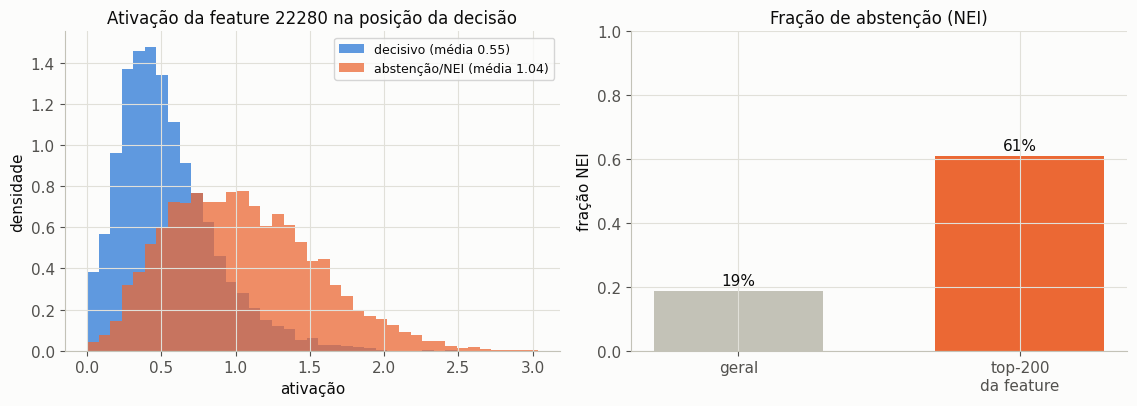

In [3]:
ex = load("../../results/v1_domain/feature_22280_examples.json")
hist = load("../../results/v1_domain/feature_22280_hist.json")

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.2))
nei = np.array(hist["nei_acts"]); dec = np.array(hist["dec_acts"])
bins = np.linspace(0, max(nei.max(), dec.max()), 40)
ax[0].hist(dec, bins=bins, color="#2a78d6", alpha=.75, label=f"decisivo (média {hist['dec_mean']:.2f})", density=True)
ax[0].hist(nei, bins=bins, color="#eb6834", alpha=.75, label=f"abstenção/NEI (média {hist['nei_mean']:.2f})", density=True)
ax[0].set_title("Ativação da feature 22280 na posição da decisão", fontsize=12, color=INK)
ax[0].set_xlabel("ativação"); ax[0].set_ylabel("densidade"); ax[0].legend(fontsize=9)
nei_top = ex.get("nei_top200", 0.61); nei_all = ex.get("nei_all", 0.19)
b = ax[1].bar(["geral", "top-200\nda feature"], [nei_all, nei_top], color=["#c3c2b7", "#eb6834"], width=.6)
ax[1].set_title("Fração de abstenção (NEI)", fontsize=12, color=INK)
ax[1].set_ylabel("fração NEI"); ax[1].set_ylim(0, 1)
for r, v in zip(b, [nei_all, nei_top]):
    ax[1].text(r.get_x()+r.get_width()/2, v+.02, f"{v:.0%}", ha="center", fontsize=11, color=INK)
plt.tight_layout(); plt.show()


**Como ler este gráfico.** *Painel da esquerda (histograma):* o eixo **X** é o valor
de ativação da feature 22280 na posição da decisão (quanto ela "acende" em cada claim);
o eixo **Y** é a densidade — a proporção de claims, normalizada dentro de cada grupo,
com aquela ativação (as duas curvas têm área 1, então dá pra comparar mesmo com números
diferentes de claims). **Azul** = claims que o modelo decidiu (SUP/REF); **laranja** =
claims em que absteve (NEI). Se a curva laranja está deslocada para a direita, a feature
ativa mais na abstenção. *Painel da direita (barras):* o eixo **Y** é a fração de claims
que são NEI; a barra **cinza** é a taxa de NEI no conjunto inteiro (linha de base) e a
**laranja** é a taxa entre os 200 claims que **mais ativam** a feature. Mostramos os dois
para responder: "quem a feature elege como top ativadores é mesmo abstenção?"

👉 **O que diz.** À esquerda: a feature 22280 ativa claramente **mais em claims que
o modelo abstém** (média 1.04) do que nos decisivos (0.55). À direita: entre os 200
claims que mais a ativam, **61% são NEI** contra **19%** na base geral (≈3.3x; no
top-50 dos dados completos chega a 98%). Não é um deslocamento sutil de média — a
feature é **seletiva** pra abstenção.

In [4]:
top = ex.get("top", [])[:12]
pd.DataFrame([{"ativação": t["act"], "rótulo": t["label"], "claim": t["claim"][:95]} for t in top])


,ativação,rótulo,claim
0,2.454,NEI,Carter Daniels ( a racist ) follows the people...
1,2.439,NEI,The deepest point of Lake Superior is slightly...
2,2.439,SUP,"In the movie The Edge of Seventeen , he introd..."
3,2.434,NEI,"Livingston , Montana , and Naganohara , Japan ..."
4,2.400,NEI,Carreño is an actor .
5,2.395,NEI,Nathan Alexander Peno is G-Eazy 's cousin .
6,2.269,REF,"The reincarnation of the Varchas , son of the ..."
7,2.264,NEI,Niagara Falls had to create a legislative dist...
8,2.260,NEI,The new CEO of Reliance Industries Limited is ...
9,2.237,SUP,His parents are Norris Sr and Diane Cole


👉 **Leitura.** Semanticamente, os claims que mais ativam a feature são
afirmações sobre **entidades obscuras/subespecificadas e trivialidades** onde a
evidência costuma ser insuficiente (ex.: *"Carreño is an actor"*, *"Band member Noah
was born in 1996"*). Ou seja, a feature captura algo como *"claim que não dá pra
verificar com confiança"* — um conceito coerente de abstenção, **não** um artefato
sintático (que era o que os SAEs oficiais davam).

### 3.3 Ablation: o texto geral ajuda a interpretabilidade?

Comparação **limpa** (v2_domain_only × v2_mixed: mesmos 120k claims de domínio e
mesmos hiperparâmetros; só muda a adição de ~25% de texto geral do Pile).

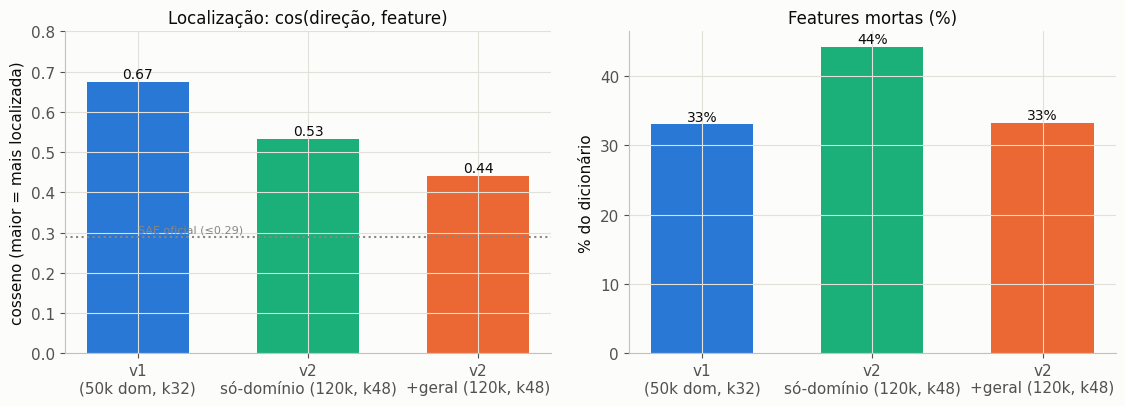

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.2))
names = list(M); cors = [M[n]["cor"] for n in names]
cos = [M[n]["abst"].get("max_decoder_cos", np.nan) for n in names]
dead = [M[n]["metrics"].get("dead_features", 0)/32768*100 for n in names]
xlab = [n.replace(" ", "\n", 1) for n in names]
b1 = ax[0].bar(xlab, cos, color=cors, width=.6)
ax[0].set_title("Localização: cos(direção, feature)", fontsize=12, color=INK)
ax[0].set_ylabel("cosseno (maior = mais localizada)"); ax[0].set_ylim(0, .8)
ax[0].axhline(0.29, ls=":", color="#898781"); ax[0].text(0, .30, "SAE oficial (≤0.29)", fontsize=8, color="#898781")
for r, v in zip(b1, cos): ax[0].text(r.get_x()+r.get_width()/2, v+.01, f"{v:.2f}", ha="center", fontsize=10)
b2 = ax[1].bar(xlab, dead, color=cors, width=.6)
ax[1].set_title("Features mortas (%)", fontsize=12, color=INK); ax[1].set_ylabel("% do dicionário")
for r, v in zip(b2, dead): ax[1].text(r.get_x()+r.get_width()/2, v+.5, f"{v:.0f}%", ha="center", fontsize=10)
plt.tight_layout(); plt.show()


**Como ler este gráfico.** Cada barra é uma das três variantes de SAE (as cores
identificam a mesma variante nos dois painéis). *Painel da esquerda:* o eixo **Y** é o
**cosseno** entre a direção de abstenção e a feature do SAE mais alinhada a ela — 0
significa "a direção não corresponde a nenhuma feature" e 1 significa "a direção **é**
uma feature". Barra mais alta = abstenção mais **condensada numa única feature**
(melhor para interpretabilidade); a linha pontilhada marca o teto dos SAEs oficiais
(≤0.29), que é o que queríamos superar. *Painel da direita:* o eixo **Y** é a **% do
dicionário que morreu** (features que nunca disparam) — quanto menor, mais aproveitado o
dicionário. Mostramos os dois lado a lado porque há um trade-off entre eles.

👉 **O que diz (ablation).** Comparando o par limpo (verde × laranja):
- **O texto geral PIOROU a localização** da abstenção: cos caiu de **0.53 → 0.44**. Ao
  aprender features gerais, o SAE "espalha" o conceito de abstenção por mais features.
- Em compensação, o texto geral **reduziu as features mortas** (44% → 33%) — mais
  diversidade de dados ativa mais features.
- E a maior localização de todas foi a **v1** (cos 0.673): menor (50k) e com k menor
  (32). Isso sugere que, para *localizar* a abstenção numa feature limpa, **menos é
  mais** — só-domínio, dicionário/k menores. (Ressalva: v1 difere do v2 em tamanho **e**
  em k, então é uma hipótese, não uma conclusão isolada.)

**Conclusão prática:** para o objetivo de *nomear* a abstenção numa feature, o
**só-domínio** vence; o texto geral só ajudou na saúde do dicionário (features mortas).

### 3.4 Generalização: a abstenção transfere para outros datasets/domínios?

O teste decisivo: pegamos a feature 22280 e a direção **aprendidas em VitaminC/FEVER**
e, **sem re-treinar nada**, aplicamos a **quatro datasets-alvo que o SAE nunca viu**, de
domínios bem diferentes:
- **AVeriTeC** (web/mundo real), **Climate-FEVER** (clima), **SciFact** (científico/
  biomédico) e **HealthVer** (saúde/COVID).

Se a feature separar abstém (NEI) vs decisivo nesses domínios, a abstenção é um
mecanismo **geral do modelo**, não um viés do estilo dos dados de treino (§2.1).

In [6]:
DOM = {"AVeriTeC\n(web)": "averitec", "Climate-FEVER\n(clima)": "climate_fever",
       "SciFact\n(ciência)": "scifact", "HealthVer\n(saúde)": "healthver"}
G = {}
for nm, key in DOM.items():
    d = load(f"../../results/v1_domain/generalize_{key}.json")
    d["_af"] = d.get("auc_feat", d.get("auc_feat_averitec"))
    d["_ad"] = d.get("auc_dir", d.get("auc_dir_averitec"))
    d["_nt"] = d.get("nei_top", d.get("nei_top200"))
    G[nm] = d
tab = pd.DataFrame([{
    "domínio": nm.replace("\n", " "), "NEI": g["n_nei"], "decisivo": g["n_dec"],
    "AUC feature": round(g["_af"], 3), "AUC direção": round(g["_ad"], 3),
    "NEI top / base": f"{g['_nt']:.0%} / {g['nei_base']:.0%} ({g['_nt']/max(g['nei_base'],1e-9):.1f}x)",
} for nm, g in G.items()]).set_index("domínio")
tab


,NEI,decisivo,AUC feature,AUC direção,NEI top / base
domínio,,,,,
AVeriTeC (web),317,3018,0.764,0.777,35% / 10% (3.7x)
Climate-FEVER (clima),474,907,0.747,0.768,70% / 34% (2.1x)
SciFact (ciência),304,957,0.844,0.601,79% / 24% (3.3x)
HealthVer (saúde),2548,3452,0.753,0.755,82% / 42% (1.9x)


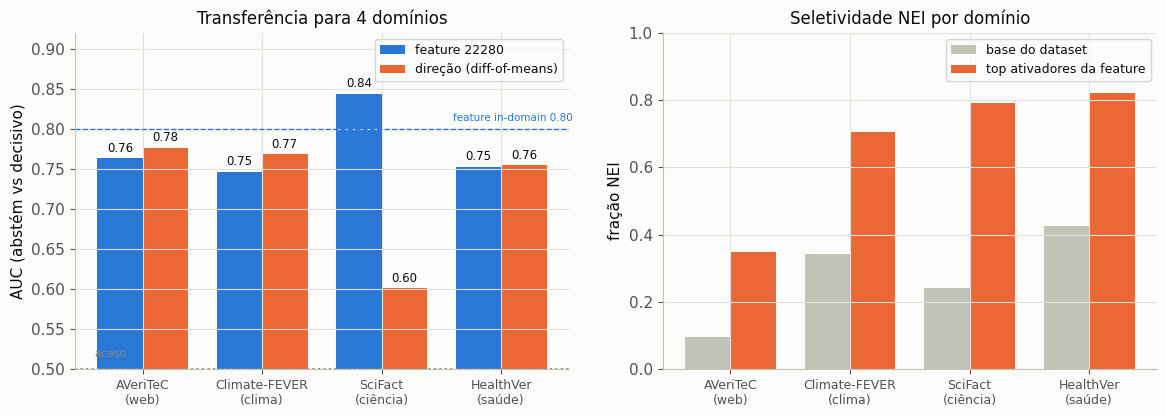

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11.8, 4.3))
names = list(G); x = np.arange(len(names)); w = 0.38
af = [G[n]["_af"] for n in names]; ad = [G[n]["_ad"] for n in names]
b1 = ax[0].bar(x - w/2, af, w, color="#2a78d6", label="feature 22280")
b2 = ax[0].bar(x + w/2, ad, w, color="#eb6834", label="direção (diff-of-means)")
ax[0].axhline(0.80, ls="--", color="#2a78d6", lw=1); ax[0].text(len(names)-1.4, .81, "feature in-domain 0.80", fontsize=7.5, color="#2a78d6")
ax[0].axhline(0.5, ls=":", color="#898781"); ax[0].text(-.4, .515, "acaso", fontsize=8, color="#898781")
ax[0].set_xticks(x); ax[0].set_xticklabels(names, fontsize=9); ax[0].set_ylim(0.5, 0.92)
ax[0].set_ylabel("AUC (abstém vs decisivo)"); ax[0].set_title("Transferência para 4 domínios", fontsize=12, color=INK)
ax[0].legend(fontsize=9)
for bars in (b1, b2):
    for r in bars: ax[0].text(r.get_x()+r.get_width()/2, r.get_height()+.008, f"{r.get_height():.2f}", ha="center", fontsize=8.5)
nt = [G[n]["_nt"] for n in names]; nb = [G[n]["nei_base"] for n in names]
b3 = ax[1].bar(x - w/2, nb, w, color="#c3c2b7", label="base do dataset")
b4 = ax[1].bar(x + w/2, nt, w, color="#eb6834", label="top ativadores da feature")
ax[1].set_xticks(x); ax[1].set_xticklabels(names, fontsize=9); ax[1].set_ylim(0, 1)
ax[1].set_ylabel("fração NEI"); ax[1].set_title("Seletividade NEI por domínio", fontsize=12, color=INK); ax[1].legend(fontsize=9)
plt.tight_layout(); plt.show()


**Como ler este gráfico.** *Painel da esquerda:* o eixo **X** agrupa os quatro
datasets-alvo (web, clima, ciência, saúde); para cada um há duas barras — **azul** = AUC
usando a **feature 22280**, **laranja** = AUC usando a **direção** completa. O eixo **Y**
é a AUC (capacidade de separar abstém vs decisivo): **0.5 = acaso** (linha pontilhada
cinza) e **1 = perfeito**. A linha azul tracejada em 0.80 marca o desempenho *in-domain*
(no VitaminC/FEVER), para enxergar quanto se perde ao transferir. *Painel da direita:*
para cada domínio, **cinza** = fração de NEI no dataset inteiro (base) e **laranja** =
fração de NEI entre os claims que mais ativam a feature; laranja acima de cinza = a
feature seleciona abstenção também naquele domínio novo.

👉 **O que diz.** A **feature 22280 transfere para os quatro domínios**: AUC
**0.75–0.84** (bem acima do acaso 0.5), chegando a **superar** o in-domain no SciFact
(0.84). E os top-ativadores da feature são majoritariamente NEI em todos (enriquecimento
**1.9x–3.7x** sobre a base). **Nuance honesta:** a **direção densa** transfere um pouco
pior no SciFact (0.60), enquanto a **feature discreta** vai muito bem (0.84) — ou seja, a
feature isolada é *mais robusta* ao domain shift científico que o vetor completo.
**Conclusão:** a abstenção descoberta em VitaminC/FEVER é um **mecanismo geral do
modelo** — generaliza para web, clima, ciência e saúde sem re-treino. Isso é o que
sustenta a ambição de contribuição: uma feature de abstenção que vale **entre datasets**
(e, como próximo passo, entre modelos).

## 4. Discussão, limitações e próximos passos

**O que deu certo.** Treinar um SAE de domínio resolveu o bloqueio central: ele
**reconstrói a posição da decisão** (FVU ≈0.24–0.31 vs ≈8–20 dos oficiais) e
**localiza a abstenção numa feature interpretável e seletiva** (v1: cos 0.673, feature
22280, 61–98% de NEI entre os top ativadores). E essa feature **generaliza para quatro
domínios distintos** — web (AVeriTeC), clima (Climate-FEVER), ciência (SciFact) e saúde
(HealthVer) — sem re-treino (§3.4), forte indício de que captura um mecanismo **geral do
modelo**, não um viés dos datasets de treino.

**O que aprendemos com o ablation.** O texto geral **não** ajudou a interpretabilidade
da abstenção (piorou a localização); ajudou só nas features mortas. Para o objetivo,
só-domínio é melhor.

**Limitações (honestas):**
- **Features mortas altas** (33–44%): o dicionário de 32.768 é grande demais para esses
  dados. Próximo ajuste: reduzir a largura e/ou tunar a esparsidade.
- **Confounds v1 × v2:** v1 difere em tamanho (50k vs 120k) **e** k (32 vs 48); a
  comparação limpa é só v2_domain_only × v2_mixed. Falta um v1 controlado (mesmo k).
- **Correlação, ainda não causalidade:** mostramos que a feature/direção *prevê* a
  abstenção (inclusive fora do domínio). Provar que a *causa* exige *steering*
  (somar/remover a direção e ver o veredito virar) — próximo passo.

**Próximos passos:** (1) *steering* causal com a direção/feature; (2) reduzir features
mortas (largura menor / tunar esparsidade); (3) publicar o SAE (Hugging Face +
Neuronpedia — o export no formato `sae_lens` já está pronto).


## Referências

- **Arditi, A., et al. (2024).** Refusal in Language Models Is Mediated by a Single Direction. *NeurIPS 2024. arXiv:2406.11717.*
- **Bricken, T., et al. (2023).** Towards Monosemanticity: Decomposing Language Models With Dictionary Learning. *Transformer Circuits (Anthropic).*
- **Cunningham, H., et al. (2023).** Sparse Autoencoders Find Highly Interpretable Features in Language Models. *arXiv:2309.08600.*
- **Gao, L., et al. (2024).** Scaling and Evaluating Sparse Autoencoders. *arXiv:2406.04093.* (TopK)
- **He, Z., et al. (2024).** Llama Scope: Extracting Millions of Features from Llama-3.1-8B. *arXiv:2410.20526.*
- **Lieberum, T., et al. (2024).** Gemma Scope: Open Sparse Autoencoders … on Gemma 2. *arXiv:2408.05147.*
- **Marks, S., & Tegmark, M. (2023).** The Geometry of Truth … *arXiv:2310.06824.* (diferença de médias)
- **Schuster, T., et al. (2021).** Get Your Vitamin C! … (VitaminC). *NAACL 2021.*
- **Templeton, A., et al. (2024).** Scaling Monosemanticity … Claude 3 Sonnet. *Transformer Circuits (Anthropic).*
- **Thorne, J., et al. (2018).** FEVER: a Large-scale Dataset for Fact Extraction and VERification. *NAACL 2018.*
